# Geração de dados com um Modelo Causal Estrutural (SCM)

Este notebook gera um conjunto de dados sintético **com estrutura causal conhecida**.

## As equações do SCM

As variáveis são geradas **nesta ordem** (causas antes dos efeitos):

| Ordem | Variável | Papel | Equação estrutural |
|---|---|---|---|
| 1 | `X1` | causa real | $X_1 := \varepsilon_1,\ \ \varepsilon_1 \sim N(0,1)$ |
| 1 | `X2` | causa real | $X_2 := \varepsilon_2,\ \ \varepsilon_2 \sim N(0,1)$ |
| 1 | `Z`  | ruído puro | $Z := \varepsilon_Z,\ \ \varepsilon_Z \sim N(0,1)$ |
| 2 | `Y`  | alvo (binário) | $Y := \mathbb{1}[\,1{,}5\,X_1 - 1{,}0\,X_2 + \varepsilon_Y > 0\,],\ \ \varepsilon_Y \sim \text{Logística}(0,1)$ |
| 3 | `S`  | **espúrio** | $S := \alpha\,(2Y-1) + \varepsilon_S,\ \ \varepsilon_S \sim N(0,1)$ |

Grafo causal: `X1 → Y ← X2`, `Y → S`, e `Z` isolado.

## Relações conhecidas com o alvo

| Atributo | Causa Y? | Relação esperada com Y | Por quê |
|---|---|---|---|
| `X1` | **sim** | positiva (r ≈ +0,49) | entra na equação de Y com peso **+1,5** |
| `X2` | **sim** | negativa (r ≈ −0,31) | entra na equação de Y com peso **−1,0**  |
| `S`  | **não** | depende de α: $r = \dfrac{\alpha}{\sqrt{\alpha^2+1}}$ | é gerado **a partir de** Y, não entra na equação de Y |
| `Z`  | **não** | nenhuma (r = 0) | não aparece em nenhuma equação junto com Y |

As relações de X1 e X2 com Y **são fixas**: a equação de Y é a mesma em todos os ambientes.
Os valores de r para X1 e X2 são aproximados, observados na simulação. O de S é exato, para
classes balanceadas.

## Como o atributo espúrio S é construído

`S` é criado **depois** de `Y`, copiando a informação de `Y` com ruído:

1. **`2Y − 1`** transforma o alvo em um sinal: Y = 0 → **−1** e Y = 1 → **+1**.
2. **× α** define a distância entre as classes. A média de S passa a ser **+α** quando Y = 1 e
   **−α** quando Y = 0.
3. **+ ε_S ~ N(0,1)** adiciona ruído, para as duas classes se sobreporem parcialmente.

Resultado: $S \mid Y{=}1 \sim N(+\alpha,\,1)$ e $S \mid Y{=}0 \sim N(-\alpha,\,1)$.

| α | O que acontece com S | Correlação esperada S–Y |
|---|---|---|
| 2,0 | classes quase totalmente separadas; S "entrega" Y | +0,89 |
| 1,0 | separação moderada | +0,71 |
| 0,5 | separação fraca | +0,45 |
| 0,0 | S vira ruído puro | 0 |
| −1,0 | relação invertida | −0,71 |
| −2,0 | relação totalmente invertida | −0,89 |

**α é o único parâmetro que muda entre os ambientes.** As equações de X1, X2, Z e Y ficam
idênticas, então a relação causal com o alvo é sempre a mesma.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
import statsmodels.api as sm

In [ ]:
# Configs

pd.set_option("display.float_format", lambda v: f"{v:.4f}")
FEATURES = ["X1", "X2", "S", "Z"]
# cor fixa por atributo (a cor segue a variável em todos os gráficos)
COR = {"X1": "#2a78d6", "X2": "#eb6834", "S": "#1baf7a", "Z": "#eda100"}
COR_CLASSE = {0: "#8a8a85", 1: "#2a78d6"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
                     "figure.dpi": 110, "font.size": 10})
SEED = 42

## Gerando os dados


In [ ]:
def gen_scm(n=2000, forca_espuria=2.0, seed=0):
    rng = np.random.default_rng(seed)
    # 1) variáveis exógenas / raízes
    X1 = rng.normal(0, 1, n)
    X2 = rng.normal(0, 1, n)
    Z  = rng.normal(0, 1, n)
    # 2) alvo: depende APENAS de X1 e X2 (mecanismo causal fixo)
    logit = 1.5 * X1 - 1.0 * X2
    Y = (logit + rng.logistic(0, 1, n) > 0).astype(int)
    # 3) espúrio: efeito de Y; a força da relação é o parâmetro que muda entre ambientes
    S = forca_espuria * (2 * Y - 1) + rng.normal(0, 1, n)
    return pd.DataFrame({"X1": X1, "X2": X2, "S": S, "Z": Z, "Y": Y})

df = gen_scm(n=2000, forca_espuria=2.0, seed=SEED)
print(df.shape)
print("Proporção de Y=1:", round(df.Y.mean(), 3))
df.head()

(2000, 5)
Proporção de Y=1: 0.484


,X1,X2,S,Z,Y
0,0.3047,-0.4520,3.6440,0.2532,1
1,-1.0400,-0.6659,1.9777,0.8952,1
2,0.7505,0.4340,-1.6825,0.2733,0
3,0.9406,0.2519,1.6050,2.2388,1
4,-1.9510,-1.4048,-3.6671,1.4298,0


## Testes estatísticos no ambiente base ($\alpha = 2$)

Para cada atributo, testamos a relação com `Y` de vários jeitos:

| Teste | O que mede |
|---|---|
| **Correlação ponto-bisserial** (Pearson com Y binário) | associação linear, com p-valor |
| **Mann-Whitney U** | se a distribuição do atributo difere entre Y=0 e Y=1 (não paramétrico) |
| **Informação mútua** | qualquer dependência, inclusive não linear (0 = independente) |
| **AUC univariada** | quão bem o atributo sozinho separa as classes (0,5 = acaso) |

In [4]:
def testes_univariados(df):
    linhas = []
    mi = mutual_info_classif(df[FEATURES], df.Y, random_state=0)
    for f, m in zip(FEATURES, mi):
        r, p_r = stats.pointbiserialr(df.Y, df[f])
        _, p_mw = stats.mannwhitneyu(df.loc[df.Y == 1, f], df.loc[df.Y == 0, f])
        auc = roc_auc_score(df.Y, df[f])
        linhas.append({"atributo": f, "r": r, "p_r": p_r, "p_mannwhitney": p_mw,
                       "info_mutua": m, "AUC": max(auc, 1 - auc)})
    t = pd.DataFrame(linhas).set_index("atributo")
    t["significativo (p<0,05)"] = np.where(t.p_r < 0.05, "sim", "não")
    return t

tab_base = testes_univariados(df)
tab_base

,r,p_r,p_mannwhitney,info_mutua,AUC,"significativo (p<0,05)"
atributo,,,,,,
X1,0.4934,0.0000,0.0000,0.1441,0.7892,sim
X2,-0.3123,0.0000,0.0000,0.0607,0.6784,sim
S,0.8880,0.0000,0.0000,0.6340,0.9979,sim
Z,-0.0255,0.2544,0.3367,0.0058,0.5124,não


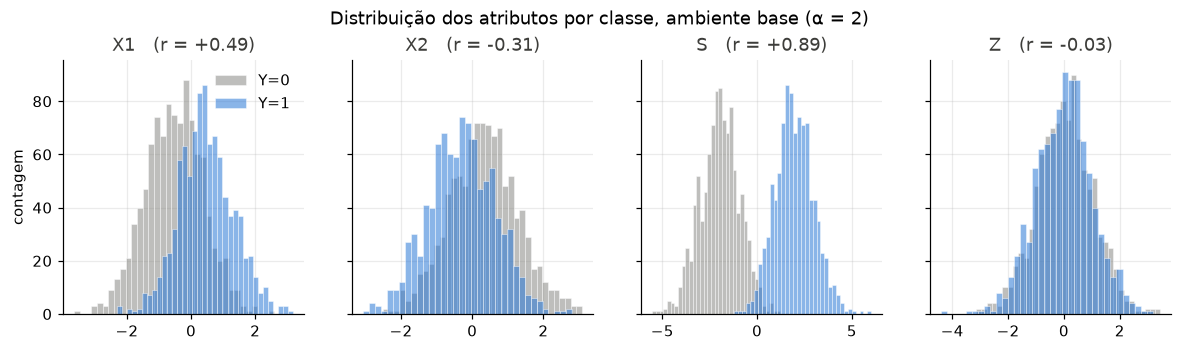

In [5]:
# Distribuição de cada atributo por classe
fig, axs = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for ax, f in zip(axs, FEATURES):
    for c in (0, 1):
        ax.hist(df.loc[df.Y == c, f], bins=35, alpha=0.55, color=COR_CLASSE[c],
                label=f"Y={c}", edgecolor="white", linewidth=0.5)
    ax.set_title(f"{f}   (r = {tab_base.loc[f, 'r']:+.2f})", color="#3d3d3a")
axs[0].set_ylabel("contagem"); axs[0].legend(frameon=False)
fig.suptitle("Distribuição dos atributos por classe, ambiente base (α = 2)", y=1.03)
plt.show()



### Regressão logística multivariada

Ajustando `Y ~ X1 + X2 + S + Z` juntos, cada coeficiente mede a contribuição *dado os outros*.

In [6]:
def logit_tabela(df, cols):
    m = sm.Logit(df.Y, sm.add_constant(df[cols])).fit(disp=0)
    return pd.DataFrame({"coef": m.params, "p_valor": m.pvalues}).drop("const")

logit_tabela(df, FEATURES)

,coef,p_valor
X1,1.9572,0.0000
X2,-1.0330,0.0000
S,4.9697,0.0000
Z,-0.0913,0.6636


## Variando S


| Ambiente | α | Significado |
|---|---|---|
| forte | 2,0 | S entrega Y quase perfeitamente (base) |
| médio | 1,0 | |
| fraco | 0,5 | |
| nulo | 0,0 | S vira ruído puro |
| invertido fraco | -1,0 | relação de S com Y se inverte |
| invertido | -2,0 | |

In [ ]:
AMBIENTES = {"forte": 2.0, "médio": 1.0, "fraco": 0.5, "nulo": 0.0,
             "invertido fraco": -1.0, "invertido": -2.0}
SEEDS = range(5)   # 5 repetições por ambiente (média ± desvio)

dados = {(amb, s): gen_scm(2000, a, seed=100 + 10 * i + s)
         for i, (amb, a) in enumerate(AMBIENTES.items()) for s in SEEDS}

# Mesmos testes univariados para cada ambiente e seed
reg = []
for (amb, s), d in dados.items():
    t = testes_univariados(d).reset_index()
    t["ambiente"], t["alpha"], t["seed"] = amb, AMBIENTES[amb], s
    reg.append(t)
res = pd.concat(reg)

# Tabela resumo: correlação r (média das seeds) de cada atributo com Y
pivot_r = res.pivot_table(index=["ambiente", "alpha"], columns="atributo", values="r",
                          aggfunc="mean", sort=False)[FEATURES]
pivot_r

,atributo,X1,X2,S,Z
ambiente,alpha,,,,
forte,2.0000,0.4949,-0.3183,0.8942,-0.0035
médio,1.0000,0.4961,-0.3138,0.7091,0.0025
fraco,0.5000,0.4844,-0.3343,0.4443,-0.0033
nulo,0.0000,0.4821,-0.3224,0.0152,-0.0118
invertido fraco,-1.0000,0.4829,-0.3016,-0.7154,-0.0078
invertido,-2.0000,0.4858,-0.3201,-0.8942,-0.0033


In [8]:
# p-valores (média das seeds): quais relações seguem significativas em cada ambiente
res.pivot_table(index=["ambiente", "alpha"], columns="atributo", values="p_r",
                aggfunc="mean", sort=False)[FEATURES].map(lambda v: f"{v:.1e}")

,atributo,X1,X2,S,Z
ambiente,alpha,,,,
forte,2.0000,1.4e-111,1.5e-42,0.0e+00,8.6e-01
médio,1.0000,7.7e-116,5.3e-41,1.8e-283,5.8e-01
fraco,0.5000,3.5e-104,2.0e-49,5.5e-92,2.0e-01
nulo,0.0000,1.3e-110,4.7e-44,4.9e-01,5.8e-01
invertido fraco,-1.0000,8.0e-102,4.7e-37,9.9e-308,6.7e-01
invertido,-2.0000,2.6e-110,4.5e-45,0.0e+00,6.2e-01


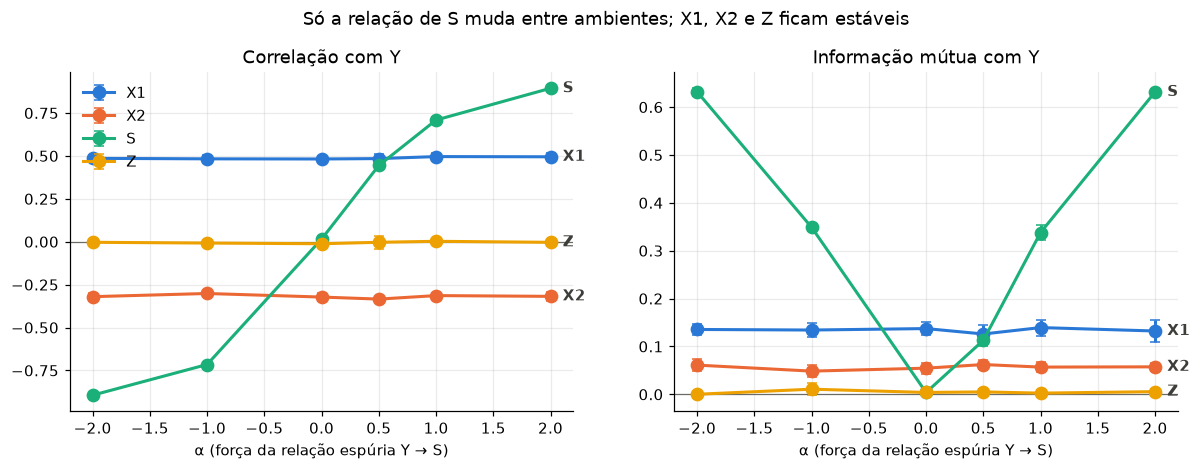

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, met, titulo in [(axs[0], "r", "Correlação com Y"), (axs[1], "info_mutua", "Informação mútua com Y")]:
    g = res.groupby(["alpha", "atributo"])[met].agg(["mean", "std"]).reset_index()
    for f in FEATURES:
        gf = g[g.atributo == f].sort_values("alpha")
        ax.errorbar(gf.alpha, gf["mean"], yerr=gf["std"], color=COR[f], lw=2,
                    marker="o", ms=8, capsize=3, label=f)
        ax.annotate(f, (gf.alpha.iloc[-1], gf["mean"].iloc[-1]), xytext=(8, 0),
                    textcoords="offset points", va="center", color="#3d3d3a", fontweight="bold")
    ax.axhline(0, color="#6b6b66", lw=0.8)
    ax.set_xlabel("α (força da relação espúria Y → S)"); ax.set_title(titulo)
axs[0].legend(frameon=False, loc="upper left")
fig.suptitle("Só a relação de S muda entre ambientes; X1, X2 e Z ficam estáveis", y=1.02)
plt.show()

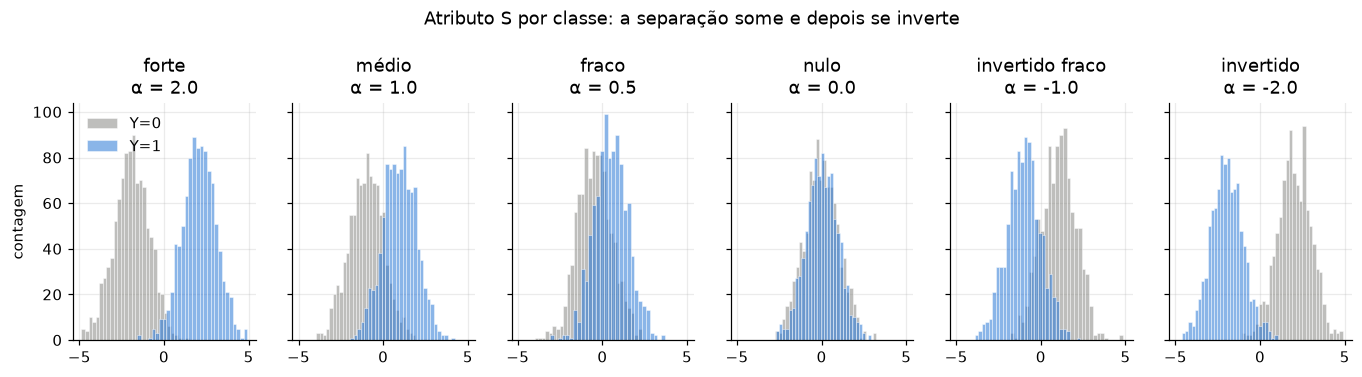

In [10]:
# Distribuição de S por classe em cada ambiente (seed 0)
fig, axs = plt.subplots(1, len(AMBIENTES), figsize=(15, 2.8), sharey=True, sharex=True)
for ax, (amb, a) in zip(axs, AMBIENTES.items()):
    d = dados[(amb, 0)]
    for c in (0, 1):
        ax.hist(d.loc[d.Y == c, "S"], bins=30, alpha=0.55, color=COR_CLASSE[c],
                label=f"Y={c}", edgecolor="white", linewidth=0.5)
    ax.set_title(f"{amb}\nα = {a}")
axs[0].legend(frameon=False); axs[0].set_ylabel("contagem")
fig.suptitle("Atributo S por classe: a separação some e depois se inverte", y=1.18)
plt.show()

### Teste de invariância: qual relação se mantém?

Esta é a ideia central para separar causa de correlação (*Invariant Causal Prediction*,
Peters et al., 2016): **o mecanismo causal é o mesmo em todos os ambientes**. Ajustamos, em cada
ambiente:

* `Y ~ X1 + X2` (só as causas): os coeficientes devem ficar **estáveis**;
* `Y ~ S` (só o espúrio): o coeficiente deve **mudar**.

In [11]:
inv = []
for (amb, s), d in dados.items():
    c_causal = logit_tabela(d, ["X1", "X2"]).coef
    c_s = logit_tabela(d, ["S"]).coef
    inv.append({"ambiente": amb, "alpha": AMBIENTES[amb], "seed": s,
                "coef_X1": c_causal["X1"], "coef_X2": c_causal["X2"], "coef_S (sozinho)": c_s["S"]})
inv = pd.DataFrame(inv)
tab_inv = inv.groupby(["ambiente", "alpha"], sort=False)[["coef_X1", "coef_X2", "coef_S (sozinho)"]].agg(["mean", "std"])
tab_inv

coef_X1        coef_X2        coef_S (sozinho)       
                           mean    std    mean    std             mean    std
ambiente        alpha                                                        
forte           2.0000   1.5668 0.1387 -1.0204 0.1008           3.9932 0.2025
médio           1.0000   1.5556 0.0685 -1.0026 0.0545           2.0257 0.1237
fraco           0.5000   1.5181 0.1359 -1.0444 0.0727           0.9986 0.0397
nulo            0.0000   1.4967 0.0243 -1.0087 0.1152           0.0309 0.0310
invertido fraco -1.0000  1.4688 0.1138 -0.9443 0.0835          -2.0631 0.0718
invertido       -2.0000  1.4899 0.0676 -0.9833 0.0510          -3.9941 0.3405

In [12]:
# Teste formal de invariância: os coeficientes diferem entre ambientes? (ANOVA entre os 6 ambientes)
for col in ["coef_X1", "coef_X2", "coef_S (sozinho)"]:
    grupos = [g[col].values for _, g in inv.groupby("ambiente")]
    F, p = stats.f_oneway(*grupos)
    veredito = "INVARIANTE (consistente com causa)" if p > 0.05 else "MUDA entre ambientes (não invariante)"
    print(f"{col:18s}  F = {F:9.2f}   p = {p:.2e}   ->  {veredito}")

coef_X1             F =      0.74   p = 6.03e-01   ->  INVARIANTE (consistente com causa)
coef_X2             F =      0.85   p = 5.28e-01   ->  INVARIANTE (consistente com causa)
coef_S (sozinho)    F =   1370.37   p = 1.18e-28   ->  MUDA entre ambientes (não invariante)


### Consequência prática: o atalho quebra

Treinamos dois modelos no ambiente **forte** e avaliamos em todos:

* **modelo causal**: usa só X1 e X2;
* **modelo completo**: usa X1, X2, S e Z (modelo "ingênuo").


In [ ]:
treino = gen_scm(2000, 2.0, seed=999)
m_causal = LogisticRegression().fit(treino[["X1", "X2"]], treino.Y)
m_full   = LogisticRegression().fit(treino[FEATURES], treino.Y)

aval = []
for (amb, s), d in dados.items():
    aval.append({"ambiente": amb, "alpha": AMBIENTES[amb],
                 "AUC causal (X1,X2)": roc_auc_score(d.Y, m_causal.predict_proba(d[["X1", "X2"]])[:, 1]),
                 "AUC completo (X1,X2,S,Z)": roc_auc_score(d.Y, m_full.predict_proba(d[FEATURES])[:, 1])})
aval = pd.DataFrame(aval)
tab_aval = aval.groupby(["ambiente", "alpha"], sort=False).mean()
tab_aval

,,"AUC causal (X1,X2)","AUC completo (X1,X2,S,Z)"
ambiente,alpha,,
forte,2.0000,0.8504,0.9986
médio,1.0000,0.8497,0.9502
fraco,0.5000,0.8485,0.8314
nulo,0.0000,0.8461,0.6233
invertido fraco,-1.0000,0.8393,0.1351
invertido,-2.0000,0.8449,0.0081


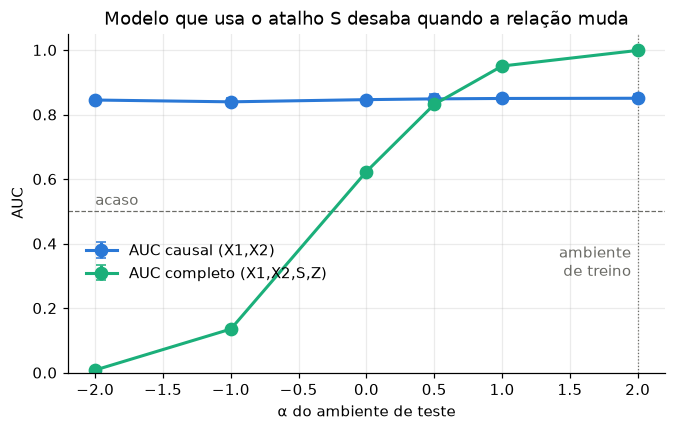

In [14]:
g = aval.drop(columns="ambiente").groupby("alpha").agg(["mean", "std"])
fig, ax = plt.subplots(figsize=(7, 4))
for col, cor in [("AUC causal (X1,X2)", "#2a78d6"), ("AUC completo (X1,X2,S,Z)", "#1baf7a")]:
    ax.errorbar(g.index, g[col]["mean"], yerr=g[col]["std"], color=cor, lw=2, marker="o",
                ms=8, capsize=3, label=col)
ax.axhline(0.5, color="#6b6b66", lw=0.8, ls="--"); ax.text(-2, 0.52, "acaso", color="#6b6b66")
ax.axvline(2.0, color="#6b6b66", lw=0.8, ls=":"); ax.text(1.95, 0.30, "ambiente\nde treino", ha="right", color="#6b6b66")
ax.set_xlabel("α do ambiente de teste"); ax.set_ylabel("AUC"); ax.set_ylim(0, 1.05)
ax.set_title("Modelo que usa o atalho S desaba quando a relação muda")
ax.legend(frameon=False, loc=(0.02, 0.25)); plt.show()

## Checagens de qualidade dos dados gerados



In [15]:
checks = []
for (amb, s), d in dados.items():
    checks.append({"ambiente": amb,
                   "prop_Y1": d.Y.mean(),                       # balanceamento das classes
                   "corr_X1_X2": d.X1.corr(d.X2),               # causas independentes entre si
                   "corr_Z_Y": d.Z.corr(d.Y),                   # Z continua sem relação
                   "corr_S_X1|Y": np.mean([np.corrcoef(g.S, g.X1)[0, 1] for _, g in d.groupby("Y")])})  # S só depende de Y
pd.DataFrame(checks).groupby("ambiente", sort=False).mean()

,prop_Y1,corr_X1_X2,corr_Z_Y,corr_S_X1|Y
ambiente,,,,
forte,0.4969,0.0037,-0.0035,-0.0132
médio,0.5041,0.0057,0.0025,0.0078
fraco,0.4995,-0.0074,-0.0033,0.0120
nulo,0.5005,0.0037,-0.0118,-0.0038
invertido fraco,0.4988,0.0109,-0.0078,-0.0075
invertido,0.4972,-0.0104,-0.0033,0.0046


## Resumo

| Atributo | Associação no ambiente base | Muda entre ambientes? | Conclusão |
|---|---|---|---|
| **X1** | forte, significativa | não | causa real |
| **X2** | forte (negativa), significativa | não | causa real |
| **S** | **a mais forte** | **sim**, some e se inverte | espúrio |
| **Z** | nenhuma | não (sempre ≈ 0) | ruído |

1. Testes de associação num único ambiente **não** distinguem causa de espúrio. S parece o melhor atributo.
2. Variando só a equação de S, a relação causal (X1, X2 → Y) fica **invariante** e a de S muda.
3. Um modelo que aproveita S tem desempenho ótimo no treino e desaba quando a relação muda.

**Próximo passo no projeto:** usar esses mesmos ambientes com o TabPFN e verificar se o **SHAP**
atribui peso a S (atalho) ou a X1 e X2 (causas). Agora há um gabarito para conferir.

In [16]:
# (opcional) salvar os conjuntos para o grupo usar os mesmos dados
import os
os.makedirs("dados_scm", exist_ok=True)
for (amb, s), d in dados.items():
    d.assign(ambiente=amb, alpha=AMBIENTES[amb], seed=s).to_csv(
        f"dados_scm/{amb.replace(' ', '_')}_seed{s}.csv", index=False)
treino.to_csv("dados_scm/treino_forte_seed999.csv", index=False)
print(len(os.listdir("dados_scm")), "arquivos salvos em dados_scm/")

31 arquivos salvos em dados_scm/
